# Nerfstudio Instant-NGP: full training on Kaggle

Canonical Kaggle kernel for training the Garden scene from scratch, then evaluating and rendering novel views.

Run on Kaggle with Internet and one GPU enabled. This notebook trains the Nerfstudio `instant-ngp` method from scratch for 30,000 iterations on the Garden COLMAP scene. Local files are source copies; GPU work runs on Kaggle.

Outputs include the final checkpoint and config, training log and environment manifest, per-image and aggregate PSNR/SSIM/LPIPS, measured inference time and GPU memory, the number of field sample queries, and a novel-view spiral video. The query count means sampled 3D positions evaluated by the neural field, not network traffic.

In [1]:
import hashlib
import importlib.metadata as metadata
import importlib.util
import json
import os
import re
import shutil
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import torch

SEED = 42
NERFSTUDIO_COMMIT = "50e0e3c70c775e89333256213363badbf074f29d"
repo = Path("/kaggle/working/nerfstudio")
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Enable a Kaggle GPU in Notebook Settings."
print("GPU:", torch.cuda.get_device_name(0))

nvcc = shutil.which("nvcc")
if nvcc is None:
    raise RuntimeError("nvcc is unavailable; tiny-cuda-nn needs the CUDA Toolkit to compile.")
nvcc_info = subprocess.run([nvcc, "--version"], text=True, capture_output=True, check=True).stdout
print(nvcc_info)
toolkit_match = re.search(r"release (\d+\.\d+)", nvcc_info)
if toolkit_match and torch.version.cuda and toolkit_match.group(1) != torch.version.cuda:
    print("CUDA toolkit and PyTorch CUDA versions differ; continuing with the Kaggle-provided runtime.")

if not repo.exists():
    subprocess.run([
        "git", "clone", "--filter=blob:none", "--no-checkout",
        "https://github.com/nerfstudio-project/nerfstudio.git", str(repo)
    ], check=True)
subprocess.run(["git", "-C", str(repo), "fetch", "--depth", "1", "origin", NERFSTUDIO_COMMIT], check=True)
subprocess.run(["git", "-C", str(repo), "checkout", "--detach", NERFSTUDIO_COMMIT], check=True)
nerfstudio_commit = subprocess.run(
    ["git", "-C", str(repo), "rev-parse", "HEAD"], text=True, capture_output=True, check=True
).stdout.strip()
assert nerfstudio_commit == NERFSTUDIO_COMMIT
print("Pinned Nerfstudio commit:", nerfstudio_commit)


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
PyTorch CUDA: 13.0
CUDA available: True
GPU: Tesla T4
nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0

M	nerfstudio/cameras/cameras.py
M	nerfstudio/utils/eval_utils.py
Pinned Nerfstudio commit: 50e0e3c70c775e89333256213363badbf074f29d


From https://github.com/nerfstudio-project/nerfstudio
 * branch              50e0e3c70c775e89333256213363badbf074f29d -> FETCH_HEAD
HEAD is now at 50e0e3c7 Add image tiling option to ColmapDataParser to use less memory (#3685)


In [2]:
# Keep Kaggle's preinstalled PyTorch/CUDA. Pin Pillow below 12 for Nerfstudio 1.1.5.
subprocess.run([sys.executable, "-m", "pip", "install", "ninja", "packaging", "Pillow<12"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-e", str(repo)], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "Pillow<12"], check=True)

# NerfAcc 0.5.2 uses cub::Equality(), removed from the CUDA 13 CUB headers.
# Patch its installed source idempotently before its CUDA extension is compiled.
nerfacc_spec = importlib.util.find_spec("nerfacc")
if nerfacc_spec is None or nerfacc_spec.origin is None:
    raise RuntimeError("nerfacc was not installed with Nerfstudio.")
nerfacc_root = Path(nerfacc_spec.origin).parent
scan_file = nerfacc_root / "cuda" / "csrc" / "scan.cu"
scan_text = scan_file.read_text(encoding="utf-8")
if "#include <thrust/functional.h>" not in scan_text:
    scan_text = "#include <thrust/functional.h>\n" + scan_text
if "cub::Equality()" in scan_text:
    scan_text = scan_text.replace("cub::Equality()", "thrust::equal_to<int64_t>()")
elif "thrust::equal_to<int64_t>()" not in scan_text:
    raise RuntimeError(f"Unexpected NerfAcc scan.cu source; inspect before patching: {scan_file}")
scan_file.write_text(scan_text, encoding="utf-8")
print("CUDA 13 compatible NerfAcc scan:", scan_file)

# PyTorch 2.6+ defaults torch.load to weights_only=True. Nerfstudio checkpoints
# contain trusted NumPy metadata and are produced by this notebook's own trainer.
eval_utils_file = repo / "nerfstudio" / "utils" / "eval_utils.py"
eval_utils_text = eval_utils_file.read_text(encoding="utf-8")
old_load = 'torch.load(load_path, map_location="cpu")'
compatible_load = 'torch.load(load_path, map_location="cpu", weights_only=False)'
if old_load in eval_utils_text:
    eval_utils_text = eval_utils_text.replace(old_load, compatible_load)
elif compatible_load not in eval_utils_text:
    raise RuntimeError(f"Could not apply PyTorch checkpoint compatibility patch: {eval_utils_file}")
eval_utils_file.write_text(eval_utils_text, encoding="utf-8")
print("Nerfstudio checkpoint load compatibility:", eval_utils_file)

# Build NVlabs tiny-cuda-nn for the active Kaggle GPU's compute capability.
env = os.environ.copy()
major, minor = torch.cuda.get_device_capability(0)
env["TCNN_CUDA_ARCHITECTURES"] = f"{major}{minor}"
print("tiny-cuda-nn CUDA architecture:", env["TCNN_CUDA_ARCHITECTURES"])
ldconfig = subprocess.run(["ldconfig", "-p"], text=True, capture_output=True, check=False).stdout
driver_candidates = re.findall(r"\s+(\/\S*libcuda\.so\.1)\s*$", ldconfig, flags=re.MULTILINE)
driver_candidates += [
    "/usr/lib/x86_64-linux-gnu/libcuda.so.1",
    "/usr/lib64/libcuda.so.1",
    "/usr/local/nvidia/lib64/libcuda.so.1",
]
driver_lib = next((Path(path) for path in driver_candidates if Path(path).is_file()), None)
if driver_lib is None:
    raise RuntimeError("Could not locate the CUDA driver library libcuda.so.1.")
link_dir = Path("/kaggle/working/cuda-link")
link_dir.mkdir(parents=True, exist_ok=True)
cuda_link = link_dir / "libcuda.so"
if cuda_link.exists() or cuda_link.is_symlink():
    cuda_link.unlink()
cuda_link.symlink_to(driver_lib)
env["LIBRARY_PATH"] = str(link_dir) + os.pathsep + env.get("LIBRARY_PATH", "")

tcnn_repo = Path("/kaggle/working/tiny-cuda-nn")
if tcnn_repo.exists():
    current_tcnn_tag = subprocess.run(
        ["git", "-C", str(tcnn_repo), "describe", "--tags", "--exact-match"],
        text=True,
        capture_output=True,
        check=False,
    )
    if current_tcnn_tag.returncode or current_tcnn_tag.stdout.strip() != "v2.0":
        shutil.rmtree(tcnn_repo)
if not tcnn_repo.exists():
    subprocess.run([
        "git", "clone", "--recursive", "--depth", "1", "--branch", "v2.0",
        "https://github.com/NVlabs/tiny-cuda-nn.git", str(tcnn_repo)
    ], check=True)
assert subprocess.run(
    ["git", "-C", str(tcnn_repo), "describe", "--tags", "--exact-match"],
    text=True,
    capture_output=True,
    check=True,
).stdout.strip() == "v2.0"
tcnn_commit = subprocess.run(
    ["git", "-C", str(tcnn_repo), "rev-parse", "HEAD"], text=True, capture_output=True, check=True
).stdout.strip()
subprocess.run([
    sys.executable, "-m", "pip", "install", "-v", "--no-build-isolation",
    str(tcnn_repo / "bindings" / "torch")
], check=True, env=env)

import tinycudann as tcnn
encoding = tcnn.Encoding(3, {
    "otype": "HashGrid", "n_levels": 2, "n_features_per_level": 2,
    "log2_hashmap_size": 4, "base_resolution": 4, "per_level_scale": 2.0,
}).cuda()
with torch.no_grad():
    encoded = encoding(torch.rand((8, 3), device="cuda"))
assert encoded.shape == (8, 4)
print("tiny-cuda-nn commit:", tcnn_commit)
print("tiny-cuda-nn CUDA smoke check:", tuple(encoded.shape))


Obtaining file:///kaggle/working/nerfstudio
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for nerfstudio (pyproject.toml): started
  Building editable for nerfstudio (pyproject.toml): finished with status 'done'
  Created wheel for nerfstudio: filename=nerfstudio-1.1.5-0.editable-py3-none-any.whl size=15809 sha256=33d52d1b72e0973640610198b0b6a1bd47417cc7e863776fd4a920ebf66680bd
  Stored in directory: /tmp/pip-ephem-wheel-cache-wyn291dj/wheels/f3/1c/b9/9643aedf2f87602c57c1a226f6d0b59eb7551819934dcd8762
Successfully built nerf

  Running command Preparing metadata (pyproject.toml)
  <string>:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  nvcc: NVIDIA (R) Cuda compiler driver
  Copyright (c) 2005-2025 NVIDIA Corporation
  Built on Wed_Aug_20_01:58:59_PM_PDT_2025
  Cuda compilation tools, release 13.0, V13.0.88
  Build cuda_13.0.r13.0/compiler.36424714_0
  /usr/local/lib/python3.13/dist-packages/setuptools/dist.py:765: SetuptoolsDeprecationWarning: License classifiers are deprecated.
  !!

          ********************************************************************************
          Please consider removing the following classifiers in favor of a SPDX license expression:

          License :: BSD 3-Clause

          See https://packaging.python.org/en/latest/guides/writing-pyproject-toml/#license for details.

  Preparing metadata (pyproject.toml): finished with status 'done'


  Running command Building wheel for tinycudann (pyproject.toml)
  <string>:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  nvcc: NVIDIA (R) Cuda compiler driver
  Copyright (c) 2005-2025 NVIDIA Corporation
  Built on Wed_Aug_20_01:58:59_PM_PDT_2025
  Cuda compilation tools, release 13.0, V13.0.88
  Build cuda_13.0.r13.0/compiler.36424714_0
  /usr/local/lib/python3.13/dist-packages/setuptools/dist.py:765: SetuptoolsDeprecationWarning: License classifiers are deprecated.
  !!

          ********************************************************************************
          Please consider removing the following classifiers in favor of a SPDX license expression:

          License :: BSD 3-Clause

          See https://packaging.python.org/en/latest/guides/writing-pyproject-toml/#license f

  Created wheel for tinycudann: filename=tinycudann-2.0-cp313-cp313-linux_x86_64.whl size=12156493 sha256=2d06f47c47d4b8fc8dd686f501371f8f9914a06de1575fd5ff3ef8cf350f4e3d
  Stored in directory: /tmp/pip-ephem-wheel-cache-9h5lv0wo/wheels/f8/52/de/d75c15d685731a11793e70a92488138d40d0224c2563252717
Successfully built tinycudann
  Attempting uninstall: tinycudann
    Found existing installation: tinycudann 2.0
    Uninstalling tinycudann-2.0:
      Removing file or directory /usr/local/lib/python3.13/dist-packages/tinycudann-2.0.dist-info/
      Removing file or directory /usr/local/lib/python3.13/dist-packages/tinycudann/
      Removing file or directory /usr/local/lib/python3.13/dist-packages/tinycudann_bindings/
      Successfully uninstalled tinycudann-2.0
tiny-cuda-nn commit: 3c7931caab7b691c6f30dffe20952ed727d935b9
tiny-cuda-nn CUDA smoke check: (8, 4)


In [3]:
input_dir = Path("/kaggle/input/mipnerf360-garden-images8")
if not input_dir.exists():
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "kagglehub"], check=True)
        import kagglehub
    input_dir = Path(kagglehub.dataset_download("nminhkhoa24120073/mipnerf360-garden-images8/versions/1"))

def is_scene_root(path: Path) -> bool:
    return (path / "images_8").is_dir() and all(
        (path / "sparse" / "0" / filename).is_file()
        for filename in ("cameras.bin", "images.bin", "points3D.bin")
    )

if not is_scene_root(input_dir):
    possible_roots = [path.parent for path in input_dir.rglob("images_8") if is_scene_root(path.parent)]
    if len(possible_roots) != 1:
        raise RuntimeError(f"Expected one Garden dataset root with images_8 and sparse/0; found {possible_roots}")
    input_dir = possible_roots[0]

scene = Path("/kaggle/working/mipnerf360-garden")
if not scene.exists():
    shutil.copytree(input_dir, scene)
images_8_dir = scene / "images_8"
images = sorted(path for path in images_8_dir.iterdir() if path.is_file())
if len(images) != 185:
    raise RuntimeError(f"Expected 185 images in images_8, found {len(images)}")
assert is_scene_root(scene)

# COLMAP intrinsics describe the original images. Nerfstudio needs the logical
# `images` directory to discover filenames, then applies factor 8 and loads the
# already-downscaled files from `images_8`. If original images are present, keep
# them; otherwise use the available image_8 files as filename placeholders.
images_dir = scene / "images"
if not images_dir.exists():
    shutil.copytree(images_8_dir, images_dir)
image_names = {path.name for path in images}
parser_image_names = {path.name for path in images_dir.iterdir() if path.is_file()}
if image_names != parser_image_names:
    raise RuntimeError("The images and images_8 directories must contain the same filenames.")

# Fail before training if the low-resolution images do not correspond to the
# COLMAP camera dimensions at the configured downscale factor.
from PIL import Image
from nerfstudio.data.utils.colmap_parsing_utils import read_cameras_binary, read_images_binary

colmap_dir = scene / "sparse" / "0"
cameras = read_cameras_binary(colmap_dir / "cameras.bin")
colmap_images = read_images_binary(colmap_dir / "images.bin")
colmap_image_names = {record.name for record in colmap_images.values()}
if colmap_image_names != image_names:
    missing = sorted(colmap_image_names - image_names)[:5]
    unregistered = sorted(image_names - colmap_image_names)[:5]
    raise RuntimeError(
        "COLMAP and images_8 filenames differ. "
        f"Missing image files: {missing}; not registered in COLMAP: {unregistered}"
    )

camera_image_sizes = {}
for record in colmap_images.values():
    camera = cameras[record.camera_id]
    image_path = images_8_dir / record.name
    with Image.open(image_path) as image:
        image_size = image.size
    expected_size = (camera.width // 8, camera.height // 8)
    if image_size != expected_size:
        raise RuntimeError(
            f"Image/COLMAP scale mismatch for {record.name}: image_8={image_size}, "
            f"COLMAP/8={expected_size} from camera {camera.id} ({camera.width}x{camera.height}). "
            "Fix the image preprocessing or downscale factor before training."
        )
    camera_image_sizes.setdefault(camera.id, set()).add(image_size)

if any(len(sizes) != 1 for sizes in camera_image_sizes.values()):
    raise RuntimeError(f"A COLMAP camera ID maps to multiple image sizes: {camera_image_sizes}")
print("Validated 185 images against COLMAP using downscale factor 8.")

digest = hashlib.sha256()
for path in [scene / "sparse" / "0" / "cameras.bin", scene / "sparse" / "0" / "images.bin", scene / "sparse" / "0" / "points3D.bin", *images]:
    digest.update(path.relative_to(scene).as_posix().encode("utf-8"))
    with path.open("rb") as content:
        for chunk in iter(lambda: content.read(1024 * 1024), b""):
            digest.update(chunk)
dataset_fingerprint = digest.hexdigest()
print("Dataset:", scene, "| images:", len(images), "| fingerprint:", dataset_fingerprint)


Validated 185 images against COLMAP using downscale factor 8.
Dataset: /kaggle/working/mipnerf360-garden | images: 185 | fingerprint: 04f971ed3fc35627f86bd5ea921c199bfd9f366af935e1e8c8d5111e39683e4e


In [ ]:
# Official full run: Nerfstudio Instant-NGP default 30,000 steps, fixed seed, COLMAP interval hold-out.
os.chdir(repo)
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
output_root = Path("/kaggle/working/outputs") / f"run-{run_id}"
train_command = [
    "ns-train", "instant-ngp",
    "--machine.num-devices", "1",
    "--machine.seed", str(SEED),
    "--max-num-iterations", "30000",
    "--steps-per-save", "2000",
    "--steps-per-eval-all-images", "30000",
    "--viewer.quit-on-train-completion", "True",
    "--output-dir", str(output_root),
    "--data", str(scene),
    "colmap", "--images-path", "images", "--colmap-path", "sparse/0",
    "--downscale-factor", "8", "--downscale-rounding-mode", "floor",
    "--eval-mode", "interval", "--eval-interval", "8",
]
print("Running:", " ".join(train_command), flush=True)
train_started_utc = datetime.now(timezone.utc).isoformat()
train_started = time.perf_counter()
train_log_path = Path("/kaggle/working/training.log")
with train_log_path.open("w", encoding="utf-8") as log_file:
    process = subprocess.Popen(
        train_command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1, env={**os.environ, "PYTHONUNBUFFERED": "1"}
    )
    assert process.stdout is not None
    for line in process.stdout:
        print(line, end="", flush=True)
        log_file.write(line)
        log_file.flush()
    train_return_code = process.wait()
training_seconds = time.perf_counter() - train_started
if train_return_code:
    raise subprocess.CalledProcessError(train_return_code, train_command)

checkpoint_candidates = list(output_root.rglob("step-*.ckpt"))
if not checkpoint_candidates:
    raise RuntimeError(f"Training finished but no checkpoint was found under {output_root}")

def checkpoint_step(path: Path) -> int:
    match = re.fullmatch(r"step-(\d+)\.ckpt", path.name)
    if match is None:
        raise RuntimeError(f"Unexpected checkpoint filename: {path.name}")
    return int(match.group(1))

checkpoint_path = max(checkpoint_candidates, key=checkpoint_step)
saved_step = checkpoint_step(checkpoint_path)
if saved_step < 29999:
    raise RuntimeError(f"Expected the final 30,000-step checkpoint (step 29999), found step {saved_step}")
print("Final checkpoint step:", saved_step)
config_path = checkpoint_path.parents[1] / "config.yml"
assert config_path.is_file(), f"Training config not found beside checkpoint: {config_path}"
run_dir = config_path.parent
artifacts = Path("/kaggle/working/experiment-artifacts")
artifact_checkpoints = artifacts / "checkpoints"
artifact_checkpoints.mkdir(parents=True, exist_ok=True)
saved_checkpoint = artifact_checkpoints / checkpoint_path.name
shutil.copy2(checkpoint_path, saved_checkpoint)
shutil.copy2(config_path, artifacts / "config.yml")
shutil.copy2(train_log_path, artifacts / "training.log")
pip_freeze = subprocess.run(
    [sys.executable, "-m", "pip", "freeze"], text=True, capture_output=True, check=True
).stdout
(artifacts / "pip-freeze.txt").write_text(pip_freeze, encoding="utf-8")
gpu_details = subprocess.run(
    ["nvidia-smi", "--query-gpu=name,driver_version,memory.total", "--format=csv"],
    text=True,
    capture_output=True,
    check=False,
).stdout.strip()

def package_version(name: str) -> str | None:
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None

run_metadata = {
    "run_id": run_id,
    "started_utc": train_started_utc,
    "training_seconds": training_seconds,
    "seed": SEED,
    "method": "instant-ngp",
    "iterations": 30000,
    "checkpoint_step": saved_step,
    "eval_mode": "interval",
    "eval_interval": 8,
    "images_path": "images",
    "downscale_factor": 8,
    "downscale_rounding_mode": "floor",
    "images": len(images),
    "dataset_fingerprint": dataset_fingerprint,
    "gpu": torch.cuda.get_device_name(0),
    "gpu_driver": gpu_details,
    "python": sys.version,
    "torch": torch.__version__,
    "torch_cuda": torch.version.cuda,
    "nerfstudio_commit": nerfstudio_commit,
    "tiny_cuda_nn_commit": tcnn_commit,
    "tiny_cuda_nn_release": "v2.0",
    "nerfacc_version": package_version("nerfacc"),
    "pillow_version": package_version("Pillow"),
    "command": train_command,
    "run_directory": str(run_dir),
    "config": str((artifacts / "config.yml").resolve()),
    "checkpoint": str(saved_checkpoint.resolve()),
}
(artifacts / "run-metadata.json").write_text(json.dumps(run_metadata, indent=2), encoding="utf-8")
print("Training finished in", round(training_seconds / 60, 2), "minutes")
print("Final checkpoint:", saved_checkpoint)


Running: ns-train instant-ngp --machine.num-devices 1 --machine.seed 42 --max-num-iterations 30000 --steps-per-save 2000 --steps-per-eval-all-images 30000 --viewer.quit-on-train-completion True --output-dir /kaggle/working/outputs/run-20261120T170224049767Z --data /kaggle/working/mipnerf360-garden colmap --images-path images --colmap-path sparse/0 --downscale-factor 8 --downscale-rounding-mode floor --eval-mode interval --eval-interval 8
/kaggle/working/nerfstudio/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float32)
/kaggle/working/nerfstudio/nerfstudio/field_components/activations.py:38: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
[17:02:33] Using --data alias for --data.pipeline.datamanager.data           

## Evaluation and reusable evaluation script

The script evaluates every image in the interval hold-out split. It records PSNR, SSIM, LPIPS, render time, GPU memory and the actual number of sampled 3D positions passed through the Instant-NGP field. It exports aggregate and per-image CSV files plus a Markdown results table and side-by-side ground-truth/prediction images.

In [10]:
%%writefile /kaggle/working/evaluate_experiment.py
"""Evaluate a Nerfstudio checkpoint and export image, timing, and field-query metrics.

The query count is the number of sampled 3D positions passed through Instant-NGP's
neural field during rendering. It is not a count of HTTP or Internet requests.
"""

from __future__ import annotations

import argparse
import csv
import json
import math
import statistics
import time
from pathlib import Path
from typing import Any

import torch
import torchvision.utils as vutils


def _mean(values: list[float]) -> float:
    return statistics.fmean(values) if values else float("nan")


def _std(values: list[float]) -> float:
    return statistics.pstdev(values) if len(values) > 1 else 0.0


def _write_csv(path: Path, rows: list[dict[str, Any]], fields: list[str]) -> None:
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)


def _write_markdown(path: Path, summary: dict[str, Any]) -> None:
    rows = [
        ("Checkpoint step", summary["checkpoint_step"]),
        ("Held-out images", summary["num_images"]),
        ("PSNR (dB), mean ± std", f"{summary['psnr_mean']:.4f} ± {summary['psnr_std']:.4f}"),
        ("SSIM, mean ± std", f"{summary['ssim_mean']:.4f} ± {summary['ssim_std']:.4f}"),
        ("LPIPS, mean ± std", f"{summary['lpips_mean']:.4f} ± {summary['lpips_std']:.4f}"),
        ("Evaluation time (s)", f"{summary['evaluation_seconds']:.3f}"),
        ("Inference time (s)", f"{summary['inference_seconds']:.3f}"),
        ("Mean render time (ms/image)", f"{summary['mean_render_ms_per_image']:.3f}"),
        ("Images / second", f"{summary['images_per_second']:.4f}"),
        ("Rays / second", f"{summary['rays_per_second']:.2f}"),
        ("Rays evaluated", summary["total_rays"]),
        ("Field sample queries", summary["field_sample_queries_total"]),
        ("Field sample queries / ray", f"{summary['field_sample_queries_per_ray']:.4f}"),
        ("Peak GPU memory (MiB)", f"{summary['peak_gpu_memory_mib']:.2f}"),
    ]
    if summary.get("training_seconds") is not None:
        rows.insert(6, ("Training time (s)", f"{summary['training_seconds']:.3f}"))
    with path.open("w", encoding="utf-8") as handle:
        handle.write("# Instant-NGP evaluation\n\n")
        handle.write("| Metric | Value |\n|---|---:|\n")
        for name, value in rows:
            handle.write(f"| {name} | {value} |\n")
        handle.write(
            "\nField sample queries count sampled 3D positions passed through the neural field during "
            "inference; they are not Internet requests or a FLOP count.\n"
        )


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--config", type=Path, required=True, help="Nerfstudio run's config.yml")
    parser.add_argument("--output-dir", type=Path, required=True)
    parser.add_argument("--training-seconds", type=float, default=None)
    parser.add_argument("--eval-rays-per-chunk", type=int, default=8192)
    parser.add_argument("--save-comparisons", action=argparse.BooleanOptionalAction, default=True)
    args = parser.parse_args()

    if not args.config.is_file():
        parser.error(f"Config not found: {args.config}")
    args.output_dir.mkdir(parents=True, exist_ok=True)
    comparison_dir = args.output_dir / "comparisons"
    if args.save_comparisons:
        comparison_dir.mkdir(parents=True, exist_ok=True)

    from nerfstudio.utils.eval_utils import eval_setup

    config, pipeline, checkpoint_path, checkpoint_step = eval_setup(
        args.config,
        eval_num_rays_per_chunk=args.eval_rays_per_chunk,
        test_mode="test",
    )
    pipeline.eval()
    model = pipeline.model
    datamanager = pipeline.datamanager
    eval_loader = datamanager.fixed_indices_eval_dataloader
    eval_dataset = datamanager.eval_dataset
    train_dataset = getattr(datamanager, "train_dataset", None)
    num_images = len(eval_dataset)
    if num_images == 0:
        raise RuntimeError("The COLMAP eval split is empty; cannot calculate image metrics.")

    if torch.cuda.is_available():
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    per_image: list[dict[str, Any]] = []
    inference_seconds = 0.0
    total_rays = 0
    total_field_queries = 0
    evaluation_started = time.perf_counter()

    with torch.inference_mode():
        for index, (camera, batch) in enumerate(eval_loader):
            height = int(camera.height.reshape(-1)[0].item())
            width = int(camera.width.reshape(-1)[0].item())
            num_rays = height * width

            if torch.cuda.is_available():
                torch.cuda.synchronize()
            render_started = time.perf_counter()
            outputs = model.get_outputs_for_camera(camera=camera)
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            render_seconds = time.perf_counter() - render_started
            inference_seconds += render_seconds

            if "num_samples_per_ray" not in outputs:
                raise RuntimeError(
                    "This model did not expose num_samples_per_ray; cannot report actual field sample queries."
                )

            prediction = outputs.get("rgb")
            ground_truth = batch.get("image")
            if prediction is not None and ground_truth is not None:
                prediction_hw = tuple(prediction.shape[-3:-1])
                ground_truth_hw = tuple(ground_truth.shape[-3:-1])
                if prediction_hw != ground_truth_hw:
                    raise RuntimeError(
                        "Rendered image and ground truth have different dimensions: "
                        f"prediction={prediction_hw}, ground_truth={ground_truth_hw}. "
                        "Check the COLMAP intrinsics and image downscale factor in config.yml."
                    )

            field_queries = int(outputs["num_samples_per_ray"].sum().item())
            total_rays += num_rays
            total_field_queries += field_queries

            image_metrics, image_outputs = model.get_image_metrics_and_images(outputs, batch)
            filename = getattr(eval_dataset, "image_filenames", [])[index]
            image_name = Path(filename).name if filename else f"eval_{index:04d}.png"
            record: dict[str, Any] = {
                "image_index": index,
                "image": image_name,
                "height": height,
                "width": width,
                "rays": num_rays,
                "field_sample_queries": field_queries,
                "field_sample_queries_per_ray": field_queries / num_rays,
                "render_seconds": render_seconds,
                "rays_per_second": num_rays / render_seconds if render_seconds > 0 else math.inf,
                **{key: float(value) for key, value in image_metrics.items()},
            }
            per_image.append(record)

            if args.save_comparisons:
                # The model returns a side-by-side [ground truth | prediction] image.
                comparison = image_outputs["img"].detach().permute(2, 0, 1).float().cpu().clamp(0, 1)
                output_name = f"{index:04d}_{Path(image_name).stem}.png"
                vutils.save_image(comparison, comparison_dir / output_name)

            print(
                f"[{index + 1}/{num_images}] {image_name}: "
                f"PSNR={record['psnr']:.3f}, SSIM={record['ssim']:.4f}, "
                f"LPIPS={record['lpips']:.4f}, field queries/ray={record['field_sample_queries_per_ray']:.2f}",
                flush=True,
            )

    if torch.cuda.is_available():
        torch.cuda.synchronize()
        peak_gpu_memory_mib = torch.cuda.max_memory_allocated() / (1024**2)
        gpu_name = torch.cuda.get_device_name(0)
    else:
        peak_gpu_memory_mib = 0.0
        gpu_name = "CPU"
    evaluation_seconds = time.perf_counter() - evaluation_started

    summary = {
        "config": str(args.config.resolve()),
        "checkpoint": str(checkpoint_path.resolve()),
        "checkpoint_step": int(checkpoint_step),
        "method": config.method_name,
        "eval_split": "COLMAP interval hold-out split",
        "num_train_images": len(train_dataset) if train_dataset is not None else None,
        "num_images": num_images,
        "total_rays": total_rays,
        "psnr_mean": _mean([row["psnr"] for row in per_image]),
        "psnr_std": _std([row["psnr"] for row in per_image]),
        "ssim_mean": _mean([row["ssim"] for row in per_image]),
        "ssim_std": _std([row["ssim"] for row in per_image]),
        "lpips_mean": _mean([row["lpips"] for row in per_image]),
        "lpips_std": _std([row["lpips"] for row in per_image]),
        "inference_seconds": inference_seconds,
        "evaluation_seconds": evaluation_seconds,
        "mean_render_ms_per_image": inference_seconds * 1000 / num_images,
        "images_per_second": num_images / inference_seconds if inference_seconds > 0 else 0.0,
        "rays_per_second": total_rays / inference_seconds if inference_seconds > 0 else 0.0,
        "field_sample_queries_total": total_field_queries,
        "field_sample_queries_per_ray": total_field_queries / total_rays if total_rays else 0.0,
        "peak_gpu_memory_mib": peak_gpu_memory_mib,
        "gpu": gpu_name,
        "training_seconds": args.training_seconds,
        "query_count_definition": (
            "sum(num_samples_per_ray): sampled 3D positions passed to the Instant-NGP neural field during inference; "
            "not Internet requests and not FLOPs"
        ),
    }

    (args.output_dir / "metrics.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    _write_csv(args.output_dir / "metrics.csv", [summary], list(summary))
    _write_csv(args.output_dir / "per-image-metrics.csv", per_image, list(per_image[0]))
    _write_markdown(args.output_dir / "metrics.md", summary)

    print(f"\nAggregate metrics: {args.output_dir / 'metrics.md'}", flush=True)
    print(json.dumps(summary, indent=2), flush=True)


if __name__ == "__main__":
    main()


Overwriting /kaggle/working/evaluate_experiment.py


In [11]:
from pathlib import Path

artifacts = Path("/kaggle/working/experiment-artifacts")
artifacts.mkdir(parents=True, exist_ok=True)
evaluation_dir = artifacts / "evaluation"
eval_command = [
    sys.executable, "/kaggle/working/evaluate_experiment.py",
    "--config", str(config_path),
    "--output-dir", str(evaluation_dir),
    "--training-seconds", str(training_seconds),
    "--eval-rays-per-chunk", "8192",
]
print("Running evaluation:", " ".join(eval_command), flush=True)
subprocess.run(eval_command, cwd=repo, check=True)


Running evaluation: /usr/bin/python3 /kaggle/working/evaluate_experiment.py --config /kaggle/working/outputs/run-20261120T170224049767Z/mipnerf360-garden/instant-ngp/2026-11-20_170233/config.yml --output-dir /kaggle/working/experiment-artifacts/evaluation --training-seconds 1528.368406992 --eval-rays-per-chunk 8192


/kaggle/working/nerfstudio/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float32)
/kaggle/working/nerfstudio/nerfstudio/field_components/activations.py:38: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd


Setting up training dataset...
Caching all 161 images.

Setting up evaluation dataset...
Caching all 24 images.

Loading latest checkpoint from load_dir
✅ Done loading checkpoint from 
/kaggle/working/outputs/run-20261120T170224049767Z/mipnerf360-garden/instant-ngp/2026-11-20_170233/nerfstudio_models/ste
p-000029999.ckpt


/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:70: FutureWarning: Importing `spectral_angle_mapper` from `torchmetrics.functional` was deprecated and will be removed in 2.0. Import `spectral_angle_mapper` from `torchmetrics.image` instead.
  _future_warning(


[1/24] DSC07956.JPG: PSNR=22.893, SSIM=0.7780, LPIPS=0.1271, field queries/ray=280.54
[2/24] DSC07964.JPG: PSNR=22.506, SSIM=0.7456, LPIPS=0.1653, field queries/ray=272.52
[3/24] DSC07972.JPG: PSNR=23.281, SSIM=0.8033, LPIPS=0.1230, field queries/ray=290.54
[4/24] DSC07980.JPG: PSNR=23.202, SSIM=0.7761, LPIPS=0.1179, field queries/ray=309.65
[5/24] DSC07988.JPG: PSNR=20.474, SSIM=0.7281, LPIPS=0.1474, field queries/ray=262.48
[6/24] DSC07996.JPG: PSNR=25.097, SSIM=0.8076, LPIPS=0.1352, field queries/ray=298.47
[7/24] DSC08004.JPG: PSNR=26.388, SSIM=0.8408, LPIPS=0.1185, field queries/ray=317.37
[8/24] DSC08012.JPG: PSNR=26.007, SSIM=0.8495, LPIPS=0.0923, field queries/ray=305.82
[9/24] DSC08020.JPG: PSNR=25.544, SSIM=0.8397, LPIPS=0.1044, field queries/ray=316.55
[10/24] DSC08028.JPG: PSNR=25.391, SSIM=0.8384, LPIPS=0.0994, field queries/ray=300.55
[11/24] DSC08036.JPG: PSNR=26.091, SSIM=0.8407, LPIPS=0.1145, field queries/ray=313.68
[12/24] DSC08044.JPG: PSNR=26.414, SSIM=0.8443, LPIP

CompletedProcess(args=['/usr/bin/python3', '/kaggle/working/evaluate_experiment.py', '--config', '/kaggle/working/outputs/run-20261120T170224049767Z/mipnerf360-garden/instant-ngp/2026-11-20_170233/config.yml', '--output-dir', '/kaggle/working/experiment-artifacts/evaluation', '--training-seconds', '1528.368406992', '--eval-rays-per-chunk', '8192'], returncode=0)

## Novel-view inference video

The renderer synthesizes a spiral camera path around a held-out camera pose, then asks the trained model to render RGB frames from those camera poses. These camera poses are generated for inference and are not among the COLMAP training images.

In [12]:
%%writefile /kaggle/working/render_novel_view.py
"""Render a spiral video from camera poses synthesized around the held-out scene."""

from __future__ import annotations

import argparse
import json
import subprocess
import time
from pathlib import Path


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--config", type=Path, required=True, help="Nerfstudio run's config.yml")
    parser.add_argument("--output", type=Path, required=True, help="Output MP4 path")
    parser.add_argument("--seconds", type=float, default=8.0)
    parser.add_argument("--fps", type=int, default=24)
    parser.add_argument("--radius", type=float, default=0.1)
    parser.add_argument("--downscale-factor", type=float, default=2.0)
    args = parser.parse_args()

    if not args.config.is_file():
        parser.error(f"Config not found: {args.config}")
    if args.seconds <= 0 or args.fps <= 0 or args.radius <= 0 or args.downscale_factor < 1:
        parser.error("seconds, fps, radius must be positive and downscale-factor must be >= 1")
    args.output.parent.mkdir(parents=True, exist_ok=True)

    command = [
        "ns-render",
        "spiral",
        "--load-config",
        str(args.config.resolve()),
        "--output-path",
        str(args.output.resolve()),
        "--seconds",
        str(args.seconds),
        "--frame-rate",
        str(args.fps),
        "--radius",
        str(args.radius),
        "--downscale-factor",
        str(args.downscale_factor),
        "--output-format",
        "video",
        "--rendered-output-names",
        "rgb",
    ]
    log_path = args.output.with_suffix(".log")
    started = time.perf_counter()
    print("Rendering synthetic camera trajectory:", " ".join(command), flush=True)
    with log_path.open("w", encoding="utf-8") as log_file:
        process = subprocess.Popen(
            command,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )
        assert process.stdout is not None
        for line in process.stdout:
            print(line, end="", flush=True)
            log_file.write(line)
            log_file.flush()
        return_code = process.wait()
    if return_code:
        raise subprocess.CalledProcessError(return_code, command)
    if not args.output.is_file() or args.output.stat().st_size == 0:
        raise RuntimeError(f"Renderer exited without creating a video: {args.output}")

    still_path = args.output.with_name(f"{args.output.stem}_frame.png")
    subprocess.run(
        [
            "ffmpeg",
            "-y",
            "-ss",
            str(args.seconds / 4),
            "-i",
            str(args.output.resolve()),
            "-frames:v",
            "1",
            str(still_path.resolve()),
        ],
        check=True,
        stdout=subprocess.DEVNULL,
        stderr=subprocess.PIPE,
        text=True,
    )
    if not still_path.is_file() or still_path.stat().st_size == 0:
        raise RuntimeError(f"ffmpeg did not create the example frame: {still_path}")

    manifest = {
        "video": str(args.output.resolve()),
        "example_novel_view_image": str(still_path.resolve()),
        "config": str(args.config.resolve()),
        "trajectory": "Nerfstudio spiral path synthesized from a held-out camera pose",
        "seconds": args.seconds,
        "fps": args.fps,
        "frames": int(args.seconds * args.fps),
        "radius": args.radius,
        "downscale_factor": args.downscale_factor,
        "render_seconds": time.perf_counter() - started,
        "size_bytes": args.output.stat().st_size,
        "command": command,
    }
    args.output.with_suffix(".json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print("Video written:", args.output, flush=True)


if __name__ == "__main__":
    main()


Overwriting /kaggle/working/render_novel_view.py


In [13]:
video_path = artifacts / "novel_view_spiral.mp4"
render_command = [
    sys.executable, "/kaggle/working/render_novel_view.py",
    "--config", str(config_path),
    "--output", str(video_path),
    "--seconds", "8",
    "--fps", "24",
    "--radius", "0.1",
    "--downscale-factor", "2",
]
print("Running novel-view render:", " ".join(render_command), flush=True)
subprocess.run(render_command, cwd=repo, check=True)


Running novel-view render: /usr/bin/python3 /kaggle/working/render_novel_view.py --config /kaggle/working/outputs/run-20261120T170224049767Z/mipnerf360-garden/instant-ngp/2026-11-20_170233/config.yml --output /kaggle/working/experiment-artifacts/novel_view_spiral.mp4 --seconds 8 --fps 24 --radius 0.1 --downscale-factor 2
Rendering synthetic camera trajectory: ns-render spiral --load-config /kaggle/working/outputs/run-20261120T170224049767Z/mipnerf360-garden/instant-ngp/2026-11-20_170233/config.yml --output-path /kaggle/working/experiment-artifacts/novel_view_spiral.mp4 --seconds 8.0 --frame-rate 24 --radius 0.1 --downscale-factor 2.0 --output-format video --rendered-output-names rgb
/kaggle/working/nerfstudio/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float32)
/kaggle/working/nerfstudio/nerfstudio/field_components

CompletedProcess(args=['/usr/bin/python3', '/kaggle/working/render_novel_view.py', '--config', '/kaggle/working/outputs/run-20261120T170224049767Z/mipnerf360-garden/instant-ngp/2026-11-20_170233/config.yml', '--output', '/kaggle/working/experiment-artifacts/novel_view_spiral.mp4', '--seconds', '8', '--fps', '24', '--radius', '0.1', '--downscale-factor', '2'], returncode=0)

## Reproduction outputs

Kaggle saves files under `/kaggle/working` when you save a notebook version with outputs. The checkpoint is also copied into `experiment-artifacts/checkpoints` so it can be downloaded with the metrics, config and video.

,Metric,Value
0,PSNR mean ± std (dB),25.4221 ± 1.7630
1,SSIM mean ± std,0.8182 ± 0.0324
2,LPIPS mean ± std,0.1151 ± 0.0180
3,Training time (s),1528.37
4,Evaluation time (s),52.90
5,Field sample queries / ray,298.4597
6,Peak GPU memory (MiB),2736.76


,image_index,image,height,width,rays,field_sample_queries,field_sample_queries_per_ray,render_seconds,rays_per_second,psnr,ssim,lpips
0,0,DSC07956.JPG,420,648,272160,76352040,280.541005,2.582331,105393.167136,22.893400,0.777972,0.127119
1,1,DSC07964.JPG,420,648,272160,74168894,272.519452,1.751198,155413.564443,22.505857,0.745587,0.165327
2,2,DSC07972.JPG,420,648,272160,79072530,290.536927,1.893575,143728.136481,23.280882,0.803323,0.123042
3,3,DSC07980.JPG,420,648,272160,84273251,309.645984,2.010909,135341.748926,23.202190,0.776143,0.117921
4,4,DSC07988.JPG,420,648,272160,71435290,262.475345,1.735687,156802.498929,20.473791,0.728074,0.147412
5,5,DSC07996.JPG,420,648,272160,81232857,298.474636,1.928644,141114.679004,25.096935,0.807592,0.135181
6,6,DSC08004.JPG,420,648,272160,86376581,317.374269,2.074638,131184.332044,26.388142,0.840839,0.118480
7,7,DSC08012.JPG,420,648,272160,83233070,305.824037,2.012959,135203.938106,26.007221,0.849546,0.092319
8,8,DSC08020.JPG,420,648,272160,86152481,316.550856,2.082501,130688.984697,25.544294,0.839736,0.104432
9,9,DSC08028.JPG,420,648,272160,81798437,300.552752,1.970476,138118.895038,25.391468,0.838429,0.099440


ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

Per-image metrics: /kaggle/working/experiment-artifacts/evaluation/per-image-metrics.csv
Saved checkpoint: /kaggle/working/experiment-artifacts/checkpoints/step-000029999.ckpt
Original video: /kaggle/working/experiment-artifacts/novel_view_spiral.mp4
Upright video: /kaggle/working/experiment-artifacts/novel_view_spiral_upright.mp4


Output #0, image2, to '/kaggle/working/experiment-artifacts/novel_view_spiral_upright_frame.png':
  Metadata:
    major_brand     : isom
    minor_version   : 512
    compatible_brands: isomiso2avc1mp41
    encoder         : Lavf60.16.100
  Stream #0:0(und): Video: png, rgb24(pc, gbr/unknown/unknown, progressive), 324x210, q=2-31, 200 kb/s, 24 fps, 24 tbn (default)
    Metadata:
      handler_name    : VideoHandler
      vendor_id       : [0][0][0][0]
      encoder         : Lavc60.31.102 png
[image2 @ 0x563410cc8f40] The specified filename '/kaggle/working/experiment-artifacts/novel_view_spiral_upright_frame.png' does not contain an image sequence pattern or a pattern is invalid.
[image2 @ 0x563410cc8f40] Use a pattern such as %03d for an image sequence or use the -update option (with -frames:v 1 if needed) to write a single image.
[out#0/image2 @ 0x563410c17900] video:168kB audio:0kB subtitle:0kB other streams:0kB global headers:0kB muxing overhead: unknown
frame=    1 fps=0.0 q=-0.0

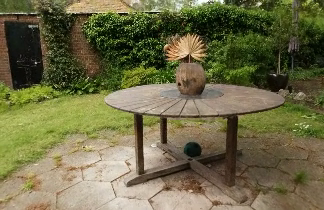

In [15]:
import json
import subprocess
from pathlib import Path

import pandas as pd
from IPython.display import Video, display
from PIL import Image

metrics = json.loads(
    (artifacts / "evaluation" / "metrics.json").read_text(encoding="utf-8")
)

scorecard = pd.DataFrame([
    {
        "Metric": "PSNR mean ± std (dB)",
        "Value": f"{metrics['psnr_mean']:.4f} ± {metrics['psnr_std']:.4f}",
    },
    {
        "Metric": "SSIM mean ± std",
        "Value": f"{metrics['ssim_mean']:.4f} ± {metrics['ssim_std']:.4f}",
    },
    {
        "Metric": "LPIPS mean ± std",
        "Value": f"{metrics['lpips_mean']:.4f} ± {metrics['lpips_std']:.4f}",
    },
    {
        "Metric": "Training time (s)",
        "Value": (
            f"{metrics['training_seconds']:.2f}"
            if metrics.get("training_seconds") is not None
            else "N/A"
        ),
    },
    {
        "Metric": "Evaluation time (s)",
        "Value": f"{metrics['evaluation_seconds']:.2f}",
    },
    {
        "Metric": "Field sample queries / ray",
        "Value": f"{metrics['field_sample_queries_per_ray']:.4f}",
    },
    {
        "Metric": "Peak GPU memory (MiB)",
        "Value": f"{metrics['peak_gpu_memory_mib']:.2f}",
    },
])

display(scorecard)
display(pd.read_csv(artifacts / "evaluation" / "per-image-metrics.csv"))

source_video = Path(video_path)
upright_video = source_video.with_name(
    f"{source_video.stem}_upright{source_video.suffix}"
)
upright_frame = upright_video.with_name(
    f"{upright_video.stem}_frame.png"
)

# Rotate every frame 180 degrees. This does not retrain the model.
subprocess.run(
    [
        "ffmpeg",
        "-y",
        "-i", str(source_video),
        "-vf", "hflip,vflip",
        "-an",
        "-c:v", "libx264",
        "-crf", "18",
        "-preset", "fast",
        "-pix_fmt", "yuv420p",
        str(upright_video),
    ],
    check=True,
)

subprocess.run(
    [
        "ffmpeg",
        "-y",
        "-ss", "2",
        "-i", str(upright_video),
        "-frames:v", "1",
        str(upright_frame),
    ],
    check=True,
)

print("Per-image metrics:", artifacts / "evaluation" / "per-image-metrics.csv")
print("Saved checkpoint:", saved_checkpoint)
print("Original video:", source_video)
print("Upright video:", upright_video)

display(Image.open(upright_frame))
display(Video(str(upright_video), embed=True, width=640))